Project Overview
The Sales Exploratory Data Analysis (EDA) project analyzes sales data to understand business performance and identify important sales patterns.
Objectives
Analyze monthly sales trends.
Identify the best-selling products.
Compare total sales across product categories.
Analyze sales performance across different regions.
Calculate total revenue, average sales, highest sale, and lowest sale.
Tools and Technologies
Python: For data analysis.
Pandas: For data manipulation and analysis.
Matplotlib: For creating charts and visualizations.
Google Colab: For writing and executing Python code.
Expected Outcome
This project helps us understand sales performance, identify popular products, and discover sales trends that can support better business decisions.

In [267]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported sucessfully!")

Libraries imported sucessfully!


In [268]:
data = {
    "Date": [
        "2026-01-05", "2026-01-10", "2026-01-15",
        "2026-02-03", "2026-02-12", "2026-02-20",
        "2026-03-02", "2026-03-15", "2026-03-25",
        "2026-04-05", "2026-04-18", "2026-04-25",
        "2026-05-05", "2026-05-15", "2026-05-28"
    ],

    "Product": [
        "Laptop", "Mouse", "Keyboard",
        "Laptop", "Phone", "Headphones",
        "Monitor", "Laptop", "Mouse",
        "Phone", "Keyboard", "Monitor",
        "Laptop", "Headphones", "Phone"
    ],

    "Category": [
        "Electronics", "Accessories", "Accessories",
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Accessories", "Electronics",
        "Electronics", "Accessories", "Electronics"
    ],

    "Quantity": [
        2, 5, 3,
        1, 4, 6,
        2, 3, 8,
        5, 4, 2,
        3, 7, 4
    ],

    "Price": [
        45000, 800, 1500,
        45000, 30000, 2500,
        12000, 45000, 800,
        30000, 1500, 12000,
        45000, 2500, 30000
    ],

    "Region": [
        "South", "North", "East",
        "West", "South", "North",
        "East", "South", "West",
        "North", "East", "South",
        "West", "North", "South"
    ]
}

df = pd.DataFrame(data)

df["Date"] = pd.to_datetime(df["Date"])

df["Sales"] = df["Quantity"] * df["Price"]

df.head()

,Date,Product,Category,Quantity,Price,Region,Sales
0,2026-01-05,Laptop,Electronics,2,45000,South,90000
1,2026-01-10,Mouse,Accessories,5,800,North,4000
2,2026-01-15,Keyboard,Accessories,3,1500,East,4500
3,2026-02-03,Laptop,Electronics,1,45000,West,45000
4,2026-02-12,Phone,Electronics,4,30000,South,120000


In [269]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape:
(15, 7)

Column Names:
['Date', 'Product', 'Category', 'Quantity', 'Price', 'Region', 'Sales']

Data Types:
Date        datetime64[ns]
Product             object
Category            object
Quantity             int64
Price                int64
Region              object
Sales                int64
dtype: object


In [270]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Date        0
Product     0
Category    0
Quantity    0
Price       0
Region      0
Sales       0
dtype: int64


In [271]:
print("Number of duplicate Rows:")
print(df.duplicated().sum())

Number of duplicate Rows:
0


In [272]:
print("Basic Statistical Summary:")
print(df.describe())

Basic Statistical Summary:
                      Date   Quantity         Price          Sales
count                   15  15.000000     15.000000      15.000000
mean   2026-03-14 12:48:00   3.933333  20240.000000   59760.000000
min    2026-01-05 00:00:00   1.000000    800.000000    4000.000000
25%    2026-02-07 12:00:00   2.500000   2000.000000   10700.000000
50%    2026-03-15 00:00:00   4.000000  12000.000000   24000.000000
75%    2026-04-21 12:00:00   5.000000  37500.000000  120000.000000
max    2026-05-28 00:00:00   8.000000  45000.000000  150000.000000
std                    NaN   1.980861  18825.165528   57385.037871


In [273]:
total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()

print("Total Sales: ₹", total_sales)
print("Average Sales: ₹", round(average_sales, 2))

Total Sales: ₹ 896400
Average Sales: ₹ 59760.0


In [274]:
product_sales = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

print("Sales by Product:")
print(product_sales)

Sales by Product:
Product
Laptop        405000
Phone         390000
Monitor        48000
Headphones     32500
Keyboard       10500
Mouse          10400
Name: Sales, dtype: int64


In [275]:
# Product-wise sales analysis

product_summary = pd.pivot_table(
    df,
    index="Product",
    values="Sales",
    aggfunc="sum"
)

product_summary = product_summary.sort_values(
    by="Sales",
    ascending=False
)

print(product_summary)

             Sales
Product           
Laptop      405000
Phone       390000
Monitor      48000
Headphones   32500
Keyboard     10500
Mouse        10400


In [276]:
result = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

print(result)

Product
Laptop        405000
Phone         390000
Monitor        48000
Headphones     32500
Keyboard       10500
Mouse          10400
Name: Sales, dtype: int64


In [277]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print("SALES BY REGION")
print("================")
print(region_sales)

SALES BY REGION
Region
South    489000
North    186500
West     186400
East      34500
Name: Sales, dtype: int64


In [278]:
print("SALES BY REGION")
print(df.groupby("Region")["Sales"].sum().sort_values(ascending=False))

SALES BY REGION
Region
South    489000
North    186500
West     186400
East      34500
Name: Sales, dtype: int64


In [279]:
best_region = df.groupby("Region")["Sales"].sum().idxmax()
best_region_sales = df.groupby("Region")["Sales"].sum().max()

print("Best Selling Region:", best_region)
print("Sales:", best_region_sales)

Best Selling Region: South
Sales: 489000


In [280]:
print("Best Selling Region:", df.groupby("Region")["Sales"].sum().idxmax())
print("Highest Sales:", df.groupby("Region")["Sales"].sum().max())

Best Selling Region: South
Highest Sales: 489000


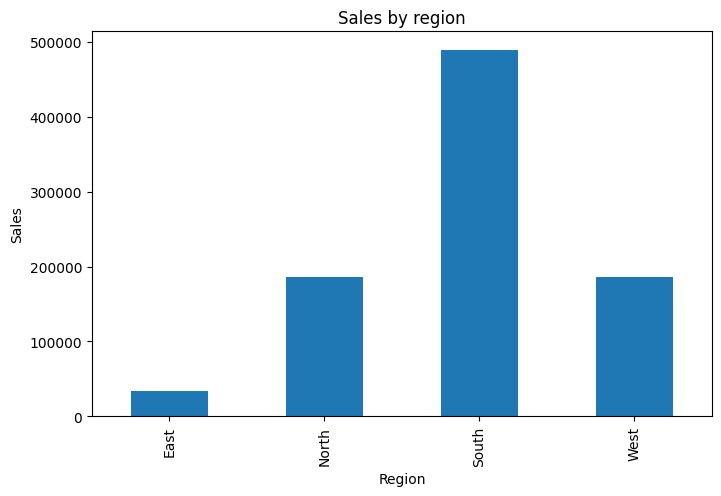

In [281]:
import matplotlib.pyplot as plt

region_sales = df.groupby("Region")["Sales"].sum()
plt.figure(figsize=(8,5))
region_sales.plot(kind="bar")
plt.title("Sales by region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.show()

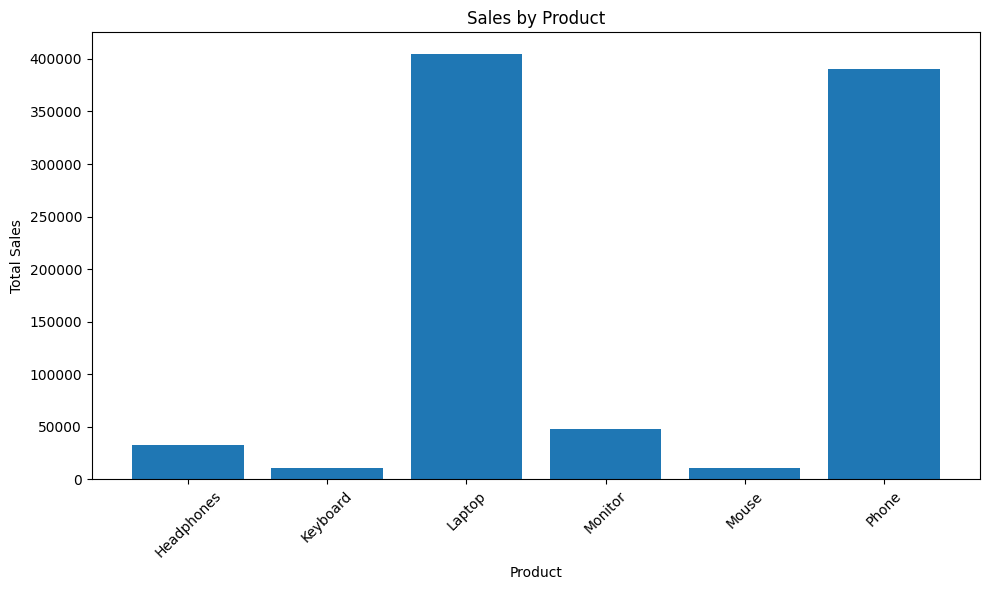

In [282]:
import matplotlib.pyplot as plt

product_sales = df.groupby("Product")["Sales"].sum()

plt.figure(figsize=(10, 6))

plt.bar(product_sales.index.astype(str), product_sales.values)

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

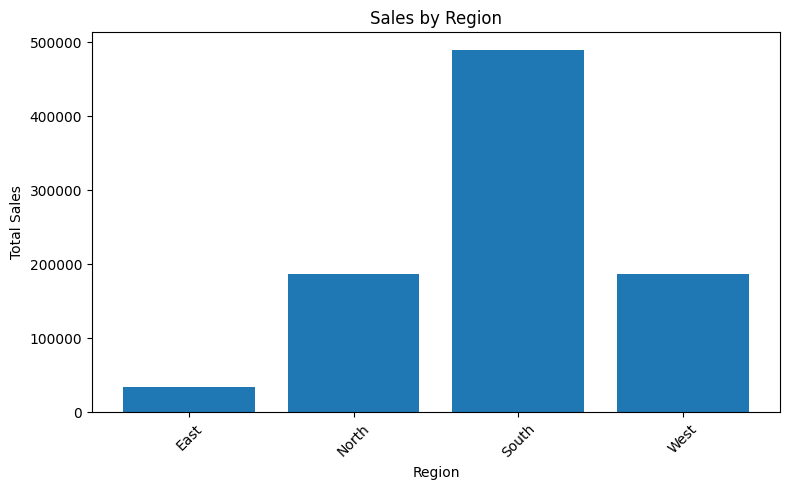

In [283]:
import matplotlib.pyplot as plt

region_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(8, 5))

plt.bar(region_sales.index.astype(str), region_sales.values)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

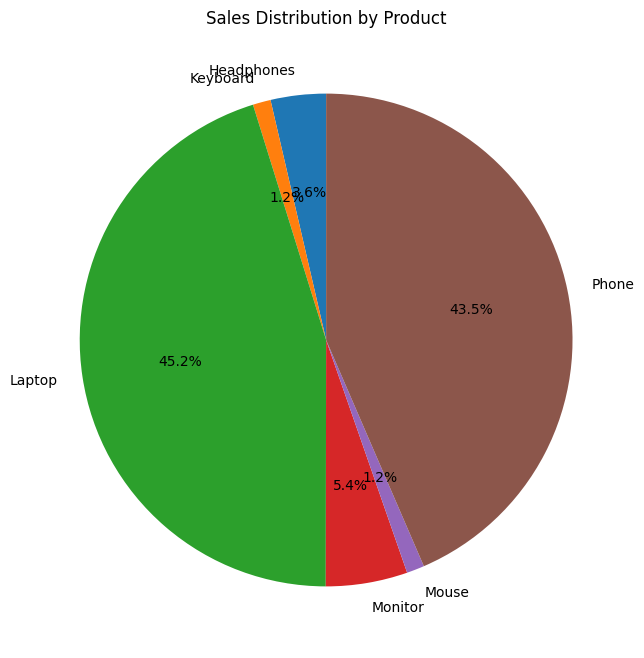

In [284]:
import matplotlib.pyplot as plt

# Calculate total sales for each product
product_sales = df.groupby("Product")["Sales"].sum()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    product_sales.values,
    labels=product_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Distribution by Product")

plt.show()

In [285]:
print(df.columns)

Index(['Date', 'Product', 'Category', 'Quantity', 'Price', 'Region', 'Sales'], dtype='object')


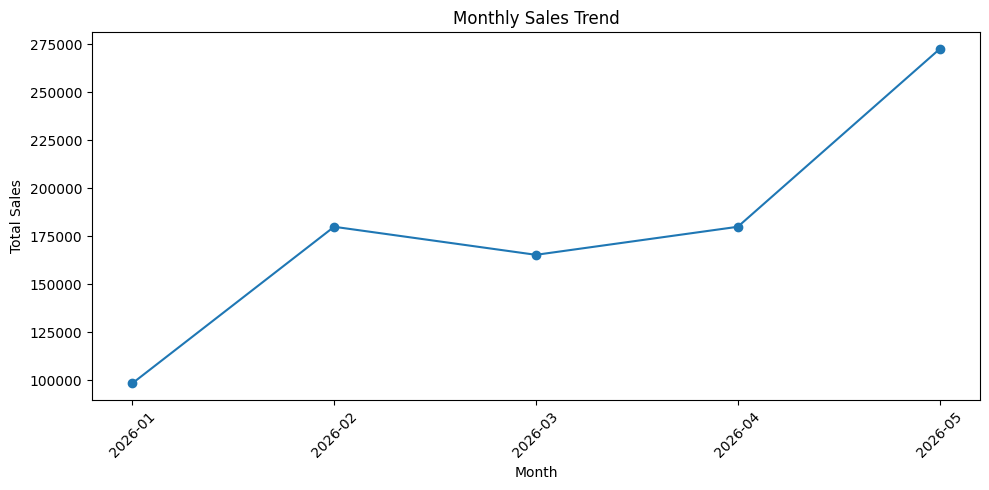

In [286]:
import matplotlib.pyplot as plt
import pandas as pd

df["Date"] = pd.to_datetime(df["Date"])

monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Sales"].sum()

plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [287]:
print(df["Date"].head())
print(df["Date"].dtype)

0   2026-01-05
1   2026-01-10
2   2026-01-15
3   2026-02-03
4   2026-02-12
Name: Date, dtype: datetime64[ns]
datetime64[ns]


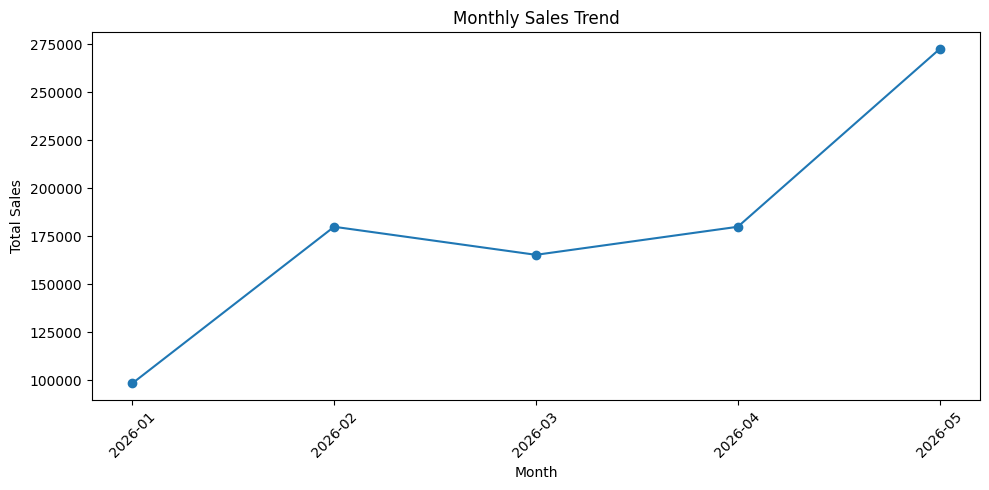

In [288]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"])

# Calculate monthly sales
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Sales"].sum()

# Create line chart
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [289]:
# Calculate total sales for each product
product_sales = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

# Display the results
print(product_sales)

Product
Laptop        405000
Phone         390000
Monitor        48000
Headphones     32500
Keyboard       10500
Mouse          10400
Name: Sales, dtype: int64


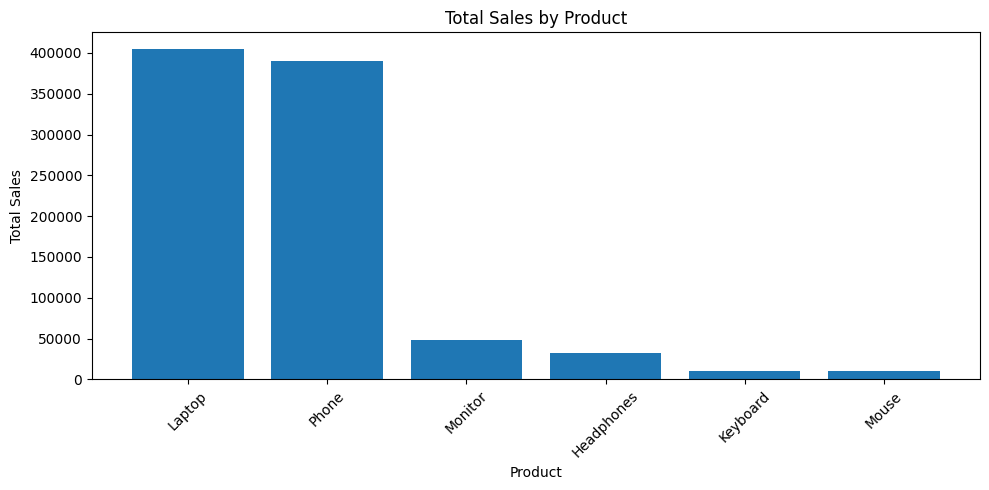

In [290]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    product_sales.index.astype(str),
    product_sales.values
)

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [291]:
# Total Sales by Region

region_sales = df.groupby("Region")["Sales"].sum()

print("Total Sales by Region:")
print(region_sales)

Total Sales by Region:
Region
East      34500
North    186500
South    489000
West     186400
Name: Sales, dtype: int64


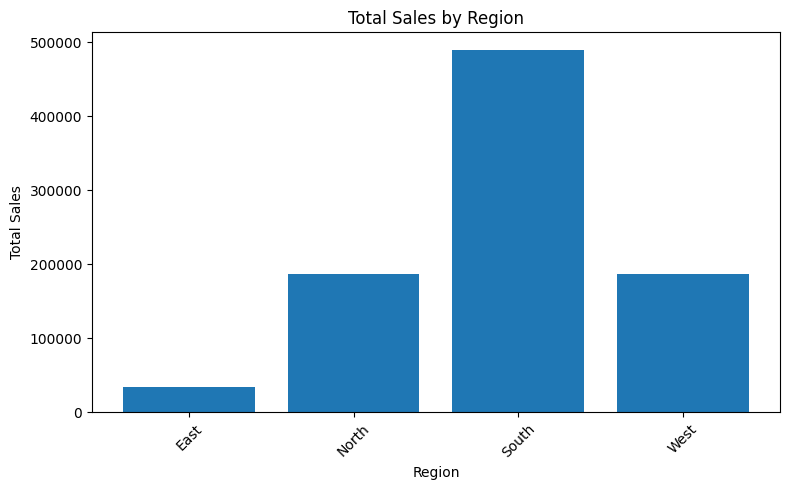

In [292]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(region_sales.index, region_sales.values)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [293]:
# Total Sales by Category

category_sales = df.groupby("Category")["Sales"].sum()

print("Total Sales by Category:")
print(category_sales)

Total Sales by Category:
Category
Accessories     53400
Electronics    843000
Name: Sales, dtype: int64


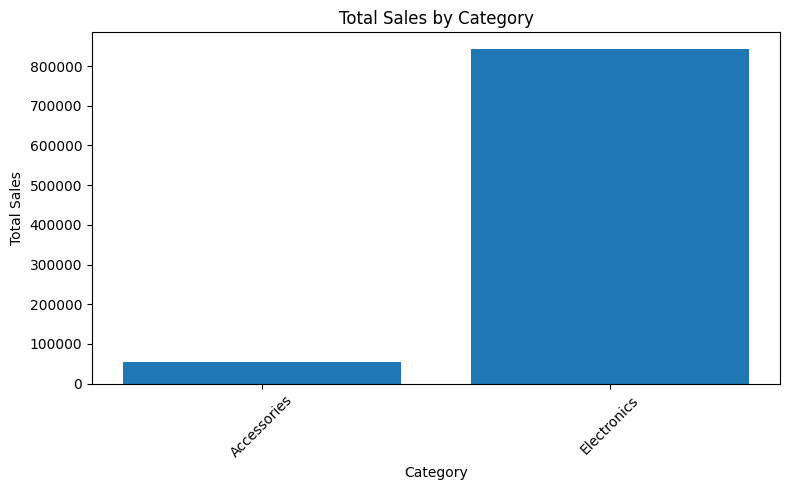

In [294]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(category_sales.index, category_sales.values)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [295]:
# Total Sales by Region

region_sales = df.groupby("Region")["Sales"].sum()

print("Total Sales by Region:")
print(region_sales)

Total Sales by Region:
Region
East      34500
North    186500
South    489000
West     186400
Name: Sales, dtype: int64


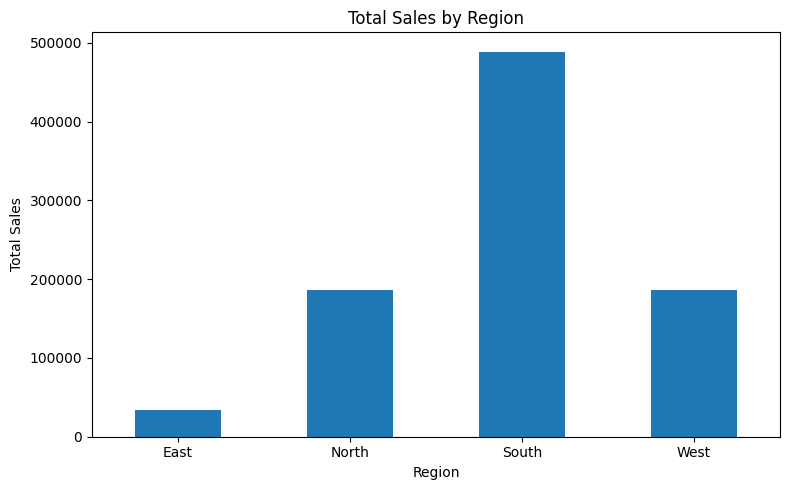

In [296]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

region_sales.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [297]:
# Find the best-selling product

product_sales = df.groupby("Product")["Sales"].sum()

top_product = product_sales.idxmax()
top_sales = product_sales.max()

print("Best-Selling Product:", top_product)
print("Total Sales:", top_sales)

Best-Selling Product: Laptop
Total Sales: 405000


In [298]:
print("Total Revenue:", df["Sales"].sum())
print("Average Sales:", df["Sales"].mean())
print("Highest Sale:", df["Sales"].max())
print("Lowest Sale:", df["Sales"].min())

Total Revenue: 896400
Average Sales: 59760.0
Highest Sale: 150000
Lowest Sale: 4000


In [299]:
# Total Sales by Region

region_sales = df.groupby("Region")["Sales"].sum()

print("Total Sales by Region:")
print(region_sales)

Total Sales by Region:
Region
East      34500
North    186500
South    489000
West     186400
Name: Sales, dtype: int64


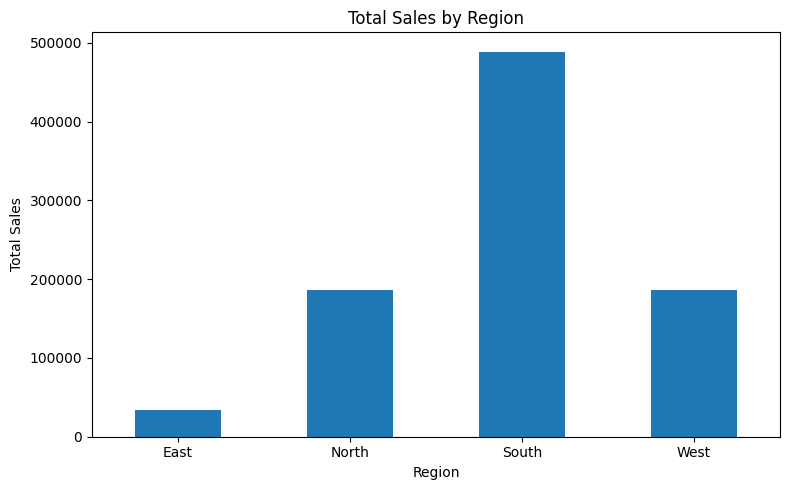

In [300]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

region_sales.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [301]:
# Find the best-selling category

category_sales = df.groupby("Category")["Sales"].sum()

best_category = category_sales.idxmax()
highest_category_sales = category_sales.max()

print("Sales by Category:")
print(category_sales)

print("\nBest-Selling Category:", best_category)
print("Total Sales:", highest_category_sales)

Sales by Category:
Category
Accessories     53400
Electronics    843000
Name: Sales, dtype: int64

Best-Selling Category: Electronics
Total Sales: 843000


In [302]:
# Final Sales Summary

print("========== SALES SUMMARY ==========")

print("Total Revenue:", df["Sales"].sum())

print("Average Sale:", round(df["Sales"].mean(), 2))

print("Best-Selling Product:",
      df.groupby("Product")["Sales"].sum().idxmax())

print("Best-Selling Category:",
      df.groupby("Category")["Sales"].sum().idxmax())

print("Highest-Sales Region:",
      df.groupby("Region")["Sales"].sum().idxmax())

print("===================================")

CONCLUSION:
The Sales Exploratory Data Analysis(EDA) project examines sales data to identify important trends and patterns.
The analysis includes:
Monthly sales trends using a line chart.
Total sales by product using a bar chart.
Total sales by category.
Regional sales comparisons.
Identification of the best-selling product.
Calculation of total revenue, average sales, highest sale, and lowest sale.
The project helps us understand sales performance, identify popular products, compare regional sales, and make better business decisions using data analysis.